# Stage 8: Explainable AI (SHAP and LIME)
## Hospital Resource Intelligence and Optimization Platform

This notebook generates, visualizes, and interprets the explainability profiles for our selected XGBoost forecasting model using both **SHAP (Shapley Additive exPlanations)** and **LIME (Local Interpretable Model-agnostic Explanations)**.

### Key Highlights:
1. **SHAP Global Interpretations**: Feature impact across the entire training dataset.
2. **SHAP Local Interpretations**: Explaining the final day's prediction step-by-step.
3. **LIME Local Interpretations**: Creating a local linear surrogate model around the final day's prediction.
4. **Academic Analysis**: Comparing XGBoost built-in feature importance vs. SHAP global values, and discussing association vs. causation.

In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
SHAP_DIR = '../outputs/explainability/shap'
LIME_DIR = '../outputs/explainability/lime'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. Global Explainability (SHAP Feature Importance)
We load the global SHAP values and render bar plots showing the average absolute impact of each feature on ICU occupancy and ED arrivals predictions.

/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_4438/2676595418.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_icu_global.head(10), x='shap_mean_abs', y='feature', palette='Purples_r')
/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_4438/2676595418.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ed_global.head(10), x='shap_mean_abs', y='feature', palette='Blues_r')


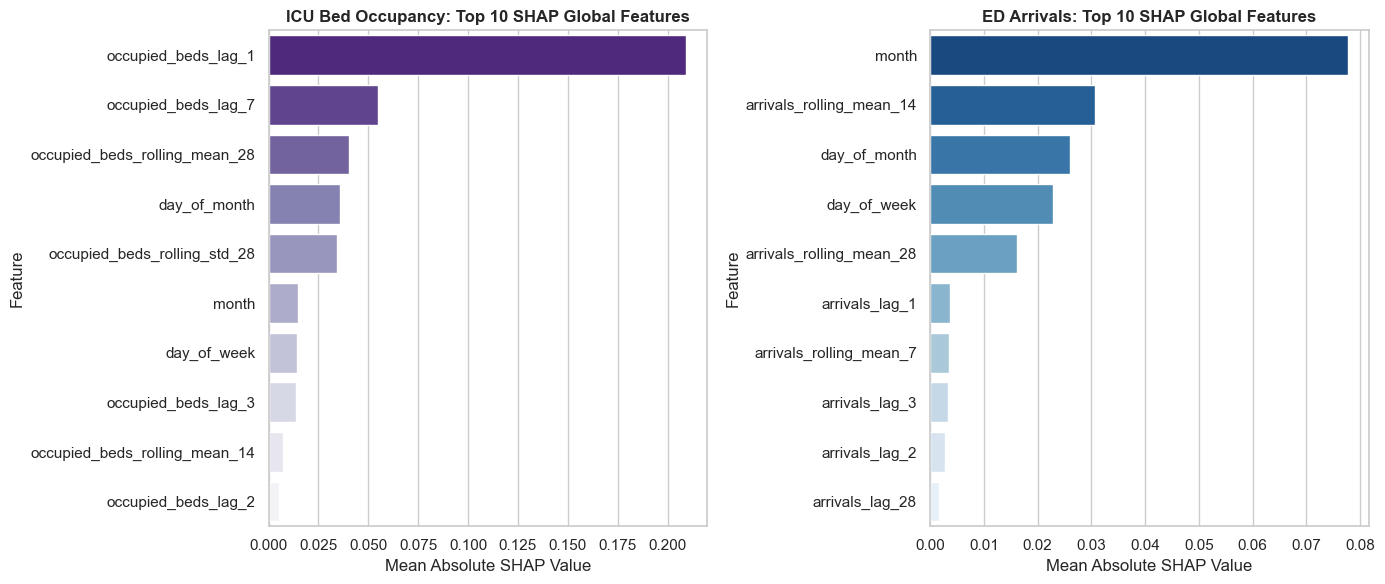

In [2]:
df_icu_global = pd.read_csv(os.path.join(SHAP_DIR, 'icu_global.csv'))
df_ed_global = pd.read_csv(os.path.join(SHAP_DIR, 'ed_global.csv'))

plt.figure(figsize=(14, 6))

# ICU
plt.subplot(1, 2, 1)
sns.barplot(data=df_icu_global.head(10), x='shap_mean_abs', y='feature', palette='Purples_r')
plt.title('ICU Bed Occupancy: Top 10 SHAP Global Features', fontsize=12, fontweight='bold')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')

# ED
plt.subplot(1, 2, 2)
sns.barplot(data=df_ed_global.head(10), x='shap_mean_abs', y='feature', palette='Blues_r')
plt.title('ED Arrivals: Top 10 SHAP Global Features', fontsize=12, fontweight='bold')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## 2. Local Explainability (SHAP Waterfall/Bar Plots)
We explain the prediction for the final test day. Features that pushed predictions higher are shown in red/orange, and those that pushed it lower in blue.

/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_4438/2318388110.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_icu_local.head(8), x='contribution', y='feature', palette=colors_icu)
/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_4438/2318388110.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ed_local.head(8), x='contribution', y='feature', palette=colors_ed)


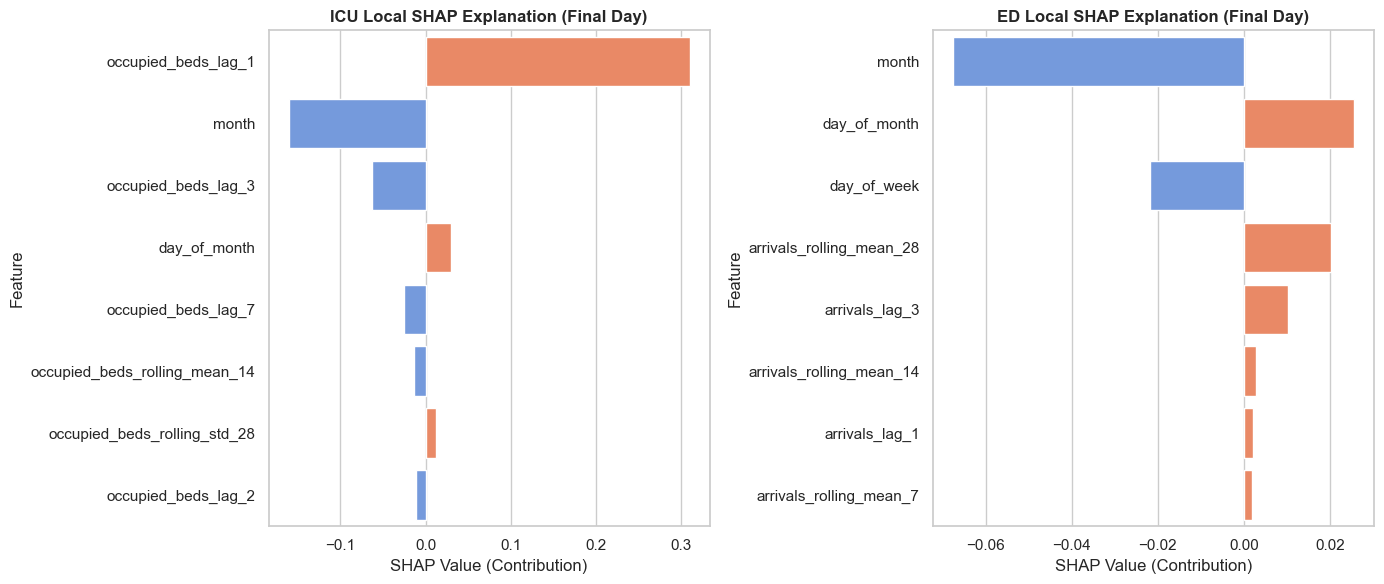

In [3]:
df_icu_local = pd.read_csv(os.path.join(SHAP_DIR, 'icu_local.csv'))
df_ed_local = pd.read_csv(os.path.join(SHAP_DIR, 'ed_local.csv'))

plt.figure(figsize=(14, 6))

# ICU
plt.subplot(1, 2, 1)
colors_icu = ['coral' if c >= 0 else 'cornflowerblue' for c in df_icu_local.head(8)['contribution']]
sns.barplot(data=df_icu_local.head(8), x='contribution', y='feature', palette=colors_icu)
plt.title('ICU Local SHAP Explanation (Final Day)', fontsize=12, fontweight='bold')
plt.xlabel('SHAP Value (Contribution)')
plt.ylabel('Feature')

# ED
plt.subplot(1, 2, 2)
colors_ed = ['coral' if c >= 0 else 'cornflowerblue' for c in df_ed_local.head(8)['contribution']]
sns.barplot(data=df_ed_local.head(8), x='contribution', y='feature', palette=colors_ed)
plt.title('ED Local SHAP Explanation (Final Day)', fontsize=12, fontweight='bold')
plt.xlabel('SHAP Value (Contribution)')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## 3. Local Explainability (LIME Tabular Explanations)
We visualize LIME local explanations for the final test day prediction to see how LIME's local linear surrogate model assigns feature weights.

/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_4438/4291841335.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_icu_lime.head(8), x='contribution', y='feature', palette=colors_lime_icu)
/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_4438/4291841335.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ed_lime.head(8), x='contribution', y='feature', palette=colors_lime_ed)


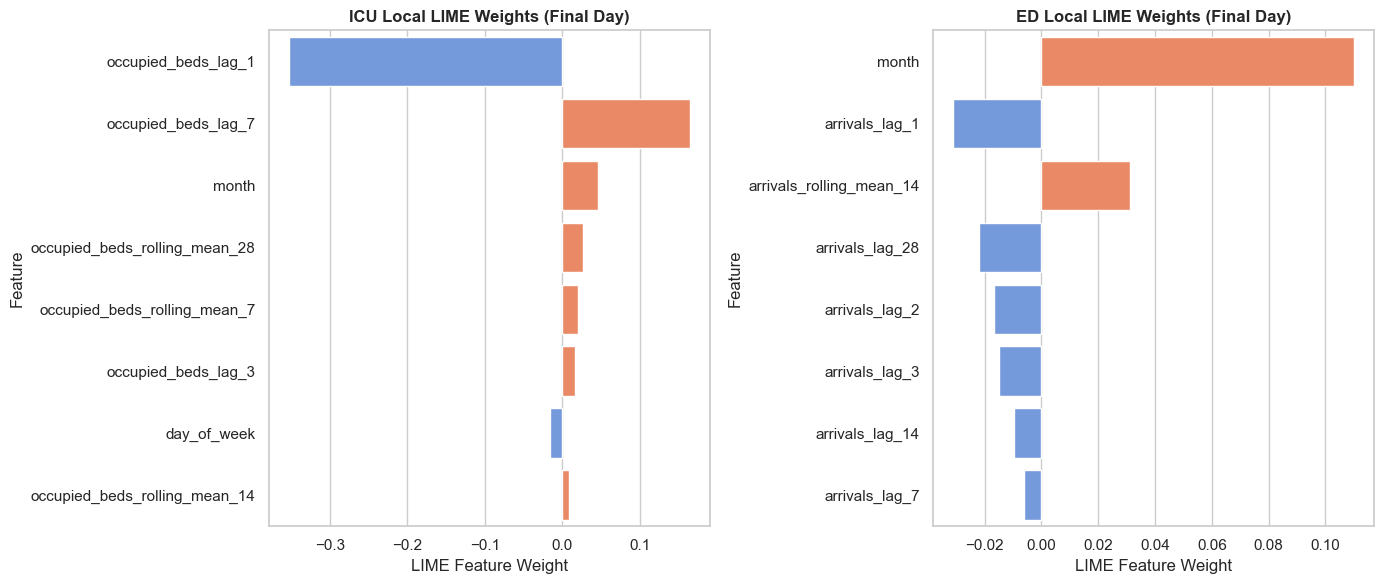

In [4]:
df_icu_lime = pd.read_csv(os.path.join(LIME_DIR, 'icu_local.csv'))
df_ed_lime = pd.read_csv(os.path.join(LIME_DIR, 'ed_local.csv'))

plt.figure(figsize=(14, 6))

# ICU
plt.subplot(1, 2, 1)
colors_lime_icu = ['coral' if c >= 0 else 'cornflowerblue' for c in df_icu_lime.head(8)['contribution']]
sns.barplot(data=df_icu_lime.head(8), x='contribution', y='feature', palette=colors_lime_icu)
plt.title('ICU Local LIME Weights (Final Day)', fontsize=12, fontweight='bold')
plt.xlabel('LIME Feature Weight')
plt.ylabel('Feature')

# ED
plt.subplot(1, 2, 2)
colors_lime_ed = ['coral' if c >= 0 else 'cornflowerblue' for c in df_ed_lime.head(8)['contribution']]
sns.barplot(data=df_ed_lime.head(8), x='contribution', y='feature', palette=colors_lime_ed)
plt.title('ED Local LIME Weights (Final Day)', fontsize=12, fontweight='bold')
plt.xlabel('LIME Feature Weight')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## 4. Feature Importance Comparison: Built-in vs. SHAP
We load the built-in feature importances saved in Stage 5 and compare their rankings with global SHAP values. They can differ because XGBoost's built-in importance is based on **gain** (split improvement), whereas SHAP is based on **Shapley values** (cooperative game theory allocation).

In [5]:
with open('../ml/forecasting/xgboost/feature_importance.json', 'r') as f:
    xgb_imp = json.load(f)

# Prepare comparison dataframe for ICU
df_xgb_icu = pd.DataFrame(list(xgb_imp['icu'].items()), columns=['feature', 'xgb_gain'])
df_compare_icu = pd.merge(df_xgb_icu, df_icu_global, on='feature')
df_compare_icu = df_compare_icu.sort_values(by='shap_mean_abs', ascending=False)
print('ICU Feature Importance Comparison:')
df_compare_icu.head(10)

ICU Feature Importance Comparison:


,feature,xgb_gain,shap_mean_abs
0,occupied_beds_lag_1,0.464155,0.209387
3,occupied_beds_lag_7,0.065078,0.054782
10,occupied_beds_rolling_mean_28,0.074375,0.040159
13,day_of_month,0.041607,0.035995
11,occupied_beds_rolling_std_28,0.058752,0.034096
14,month,0.075477,0.014643
12,day_of_week,0.030148,0.014106
2,occupied_beds_lag_3,0.045521,0.013783
8,occupied_beds_rolling_mean_14,0.068079,0.007305
1,occupied_beds_lag_2,0.010630,0.005125


## 5. Academic Discussion
1. **Association vs. Causation**:
   - **SHAP and LIME explain the model, not reality.** If `occupied_beds_lag_1` has a positive contribution of `0.31` beds, it means *the trained model* adjusts its prediction upward by 0.31 because lag_1 was high. It does not prove that yesterday's beds *caused* today's occupancy to increase.
2. **Built-in vs. SHAP Differences**:
   - XGBoost built-in importance measures the split gain. A feature that is used at the root of many trees gets high weight, even if its actual numerical output impact is minor. SHAP calculates exact marginal contributions, reflecting physical target impact.
3. **Small-Data Limitation**:
   - Since the dataset spans 180 days, global SHAP feature profiles are highly sensitive to small shifts in data. These explainability outputs should be viewed as descriptive summaries of model behavior rather than universal clinical indicators.